# Docking small molecules against an alpha-synuclein fibril

This notebook reads the files written by `run_pipeline.py`. It does not dock
anything itself, so it runs in a second or two.

The question is narrow and answerable: **can a standard AutoDock Vina setup,
pointed at a binding site on alpha-synuclein that was actually observed by
cryo-EM, tell published alpha-synuclein binders apart from unrelated approved
drugs?**

The honest answer is in the redocking control, which comes first because it
decides how much weight anything after it can carry.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RESULTS = Path.cwd().parent / "results"

summary = json.loads((RESULTS / "summary.json").read_text())
results = pd.read_csv(RESULTS / "docking_results.csv")
enrichment = pd.read_csv(RESULTS / "enrichment.csv")

print(f"{len(results)} compounds docked into {summary['receptor']['pdb_id']}")

58 compounds docked into 7YNM


## 1. The receptor and the site

PDB **7YNM** is a cryo-EM alpha-synuclein fibril with Thioflavin-T resolved in
its binding channel. That choice matters: the docking box is placed on a site
someone measured, not on a pocket guessed from the sequence, and it leaves a
ligand whose pose can be used as a control.

A fibril repeats the same subunit every ~4.8 A along its axis, so the same
binding site repeats too, and several equivalent copies of it fall inside any
practical docking box. That is handled when poses are scored, not by shrinking
the box.

In [2]:
receptor = summary["receptor"]
for key in (
    "pdb_id", "ligand_code", "n_ligand_copies", "n_symmetry_copies_in_box",
    "box_center", "box_size", "site_residues",
):
    print(f"{key:28s} {receptor[key]}")

pdb_id                       7YNM
ligand_code                  TFX
n_ligand_copies              8
n_symmetry_copies_in_box     3
box_center                   [176.891, 169.842, 150.51]
box_size                     [28.532, 19.382, 19.252]
site_residues                ['TYR39', 'GLU46', 'LYS80', 'THR81', 'VAL82']


## 2. The control: can the setup rebuild a pose we already know?

Thioflavin-T is redocked into the site it was resolved in, and the pose is
compared with the deposited coordinates. The usual pass mark is 2 A on the
**top-ranked** pose.

Two receptors are tested:

- **apo** — every dye molecule stripped out. This is what the screen uses, and
  it is the realistic situation: a drug would have to bind a fibril with no dye
  in it.
- **holo** — the neighbouring dye copies kept, one slot emptied. Thioflavin-T
  stacks along the fibril, so part of each site's wall is built from its own
  neighbours; removing all of them deletes real binding surface.

In [3]:
control = pd.DataFrame(summary["redock_control"]).T[
    ["best_score", "top_pose_rmsd", "best_pose_rmsd", "best_pose_rank", "passes_2A_top_pose"]
]
control.index.name = "receptor"
display(control)

for name, entry in summary["redock_control"].items():
    print(f"{name:5s} per-pose RMSD to nearest crystal copy: {entry['all_pose_rmsds']}")

,best_score,top_pose_rmsd,best_pose_rmsd,best_pose_rank,passes_2A_top_pose
receptor,,,,,
apo,-5.336,9.43,6.25,9,False
holo,-8.819,8.04,2.79,7,False


apo   per-pose RMSD to nearest crystal copy: [9.43, 9.38, 8.77, 9.22, 7.87, 7.82, 8.05, 8.0, 6.25]
holo  per-pose RMSD to nearest crystal copy: [8.04, 8.3, 7.94, 3.15, 4.39, 5.06, 2.79, 5.66, 5.76]


## 3. The screen

Eight compounds with published evidence of binding alpha-synuclein or altering
its aggregation, against fifty approved drugs from unrelated therapeutic areas.

Every SMILES is resolved from PubChem by name and its molecular formula checked
against a formula recorded in the source, so a wrong lookup fails loudly rather
than quietly docking the wrong molecule.

In [4]:
cols = ["name", "label", "best_score", "ligand_efficiency", "heavy_atoms", "mw", "lipinski_violations"]
print("Top 15 by Vina score\n")
display(results[cols].head(15))

print("\nWhere the reference compounds landed\n")
refs = results[results["label"] == "reference"].copy()
refs["rank"] = refs.index + 1
display(refs[["rank"] + cols])

Top 15 by Vina score



,name,label,best_score,ligand_efficiency,heavy_atoms,mw,lipinski_violations
0,Congo red,reference,-8.115,-0.1764,46,650.70,3
1,risperidone,decoy,-7.539,-0.2513,30,410.49,0
2,epigallocatechin gallate,reference,-7.263,-0.2201,33,458.38,2
3,tadalafil,decoy,-7.240,-0.2497,29,389.41,0
4,prednisone,decoy,-7.139,-0.2746,26,358.43,0
5,methotrexate,decoy,-7.017,-0.2126,33,454.45,0
6,anle138b,reference,-6.920,-0.3295,21,343.18,0
7,dexamethasone,decoy,-6.857,-0.2449,28,392.47,0
8,sildenafil,decoy,-6.747,-0.2045,33,474.59,0
9,montelukast,decoy,-6.672,-0.1627,41,586.20,2



Where the reference compounds landed



,rank,name,label,best_score,ligand_efficiency,heavy_atoms,mw,lipinski_violations
0,1,Congo red,reference,-8.115,-0.1764,46,650.70,3
2,3,epigallocatechin gallate,reference,-7.263,-0.2201,33,458.38,2
6,7,anle138b,reference,-6.920,-0.3295,21,343.18,0
10,11,SynuClean-D,reference,-6.594,-0.2638,25,354.20,0
23,24,baicalein,reference,-6.134,-0.3067,20,270.24,0
27,28,curcumin,reference,-5.909,-0.2189,27,368.39,0
40,41,Thioflavin T,reference,-5.336,-0.2668,20,283.42,0
52,53,fasudil,reference,-4.410,-0.2205,20,291.38,0


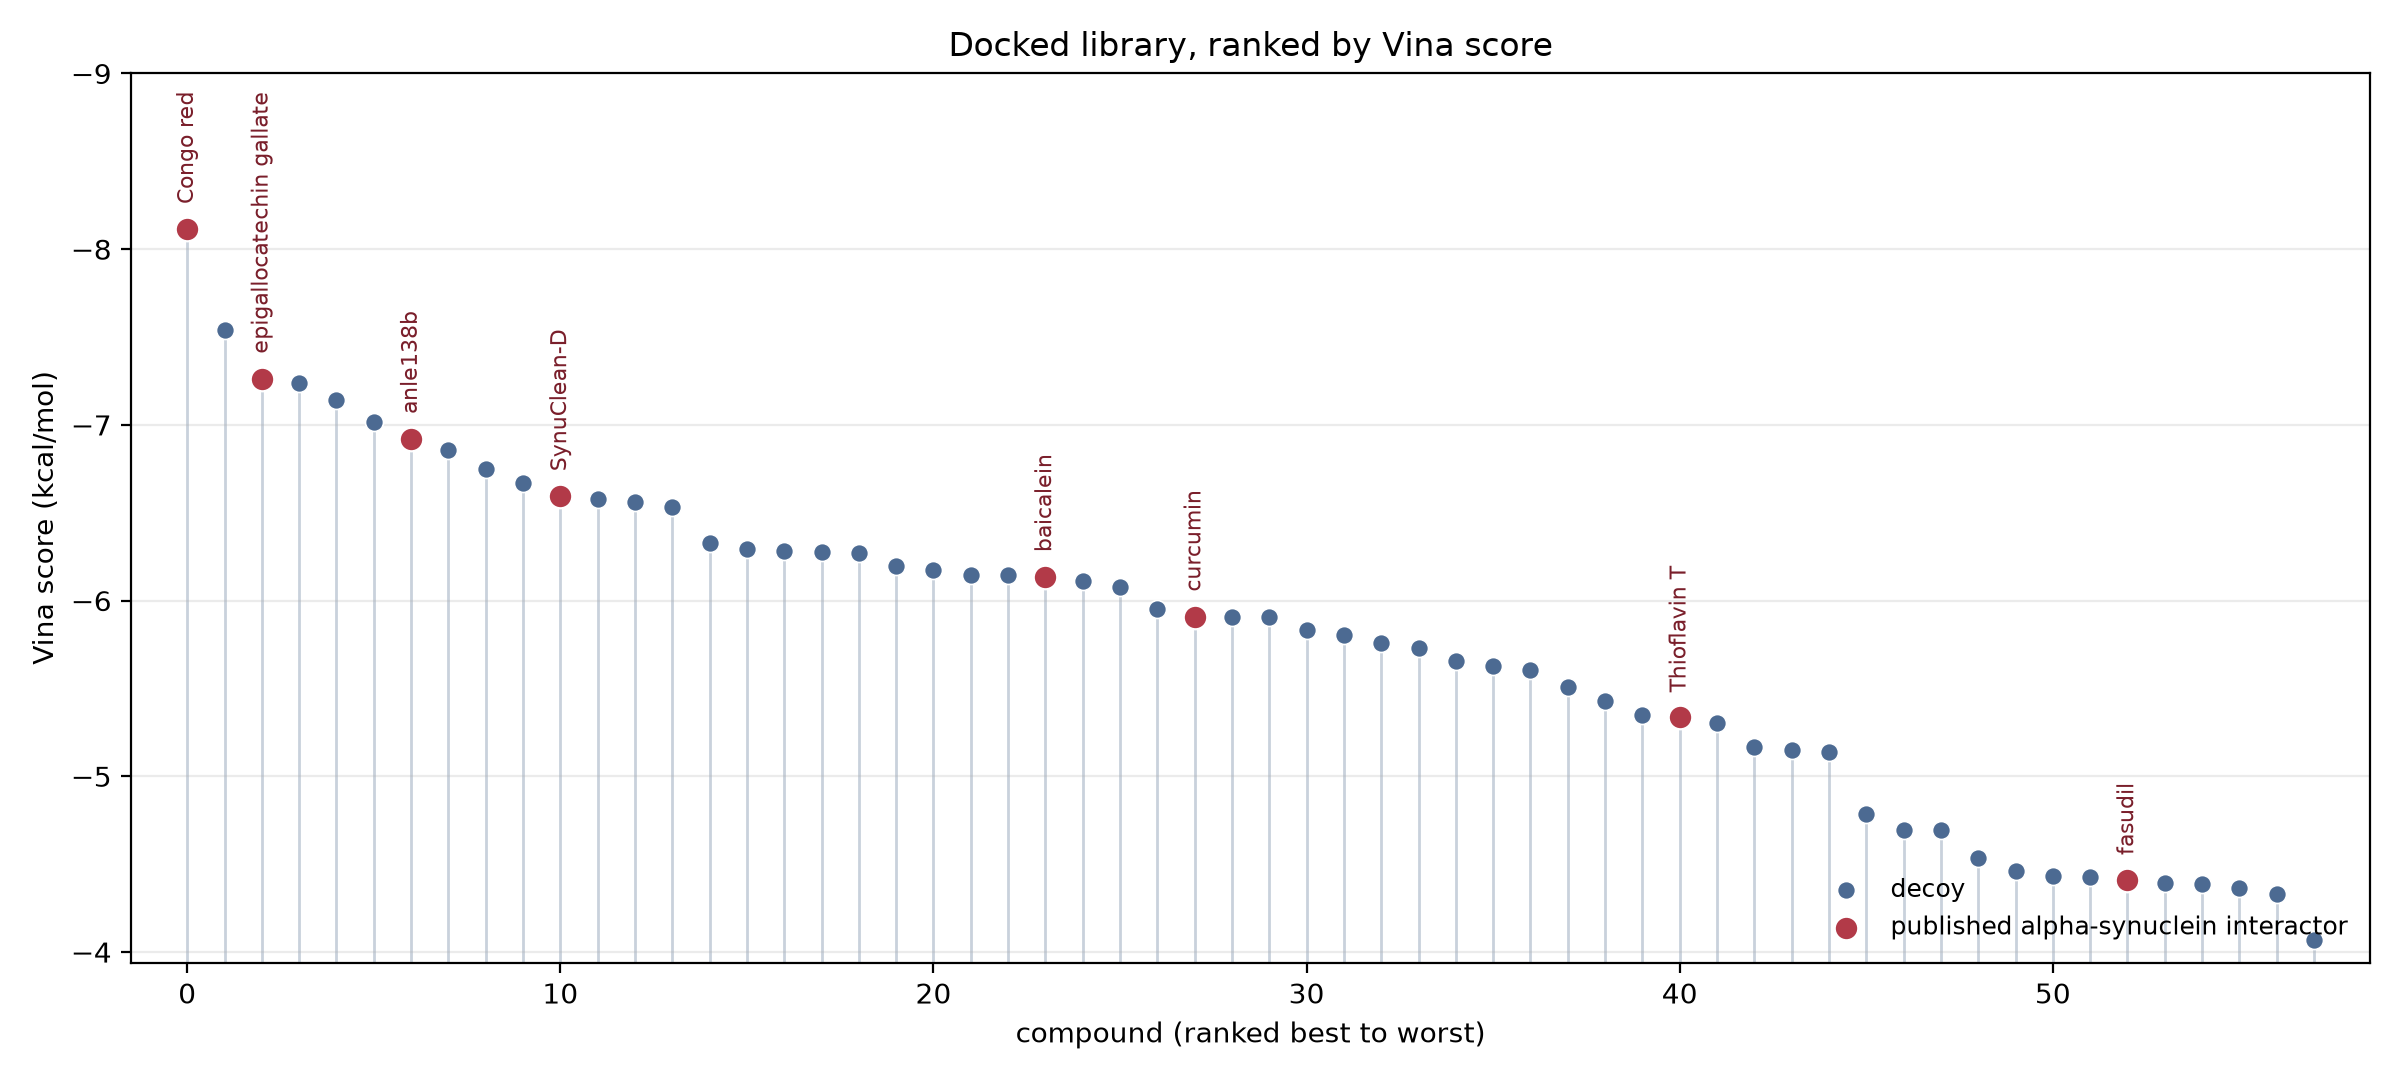

In [5]:
display(Image(filename=str(RESULTS / "figures" / "ranked_library.png")))

## 4. Do the known binders rank above the decoys?

This is a ranking question, so it gets ranking statistics: a Mann-Whitney U
test and the ROC AUC that falls out of it. AUC 0.5 means the protocol is
guessing; 1.0 means every reference outranks every decoy.

The same test is repeated on **ligand efficiency** (score divided by heavy-atom
count). Vina scores grow with molecular size, so a result that holds on raw
score but vanishes on efficiency is a size effect wearing a lab coat.

In [6]:
stats = pd.DataFrame([summary["ranking_by_score"], summary["ranking_by_ligand_efficiency"]])
display(stats.set_index("column"))
display(enrichment)

,n_reference,n_decoy,reference_median,decoy_median,u_statistic,p_value,p_value_is_one_sided,roc_auc,rank_biserial
column,,,,,,,,,
best_score,8,50,-6.364,-5.819,132.0,0.063991,True,0.670,0.34
ligand_efficiency,8,50,-0.242,-0.264,226.0,0.724936,True,0.435,-0.13


,top_fraction,n_screened,references_found,references_total,hit_rate,baseline_rate,enrichment_factor
0,0.05,3,2,8,0.667,0.138,4.83
1,0.10,6,2,8,0.333,0.138,2.42
2,0.20,12,4,8,0.333,0.138,2.42


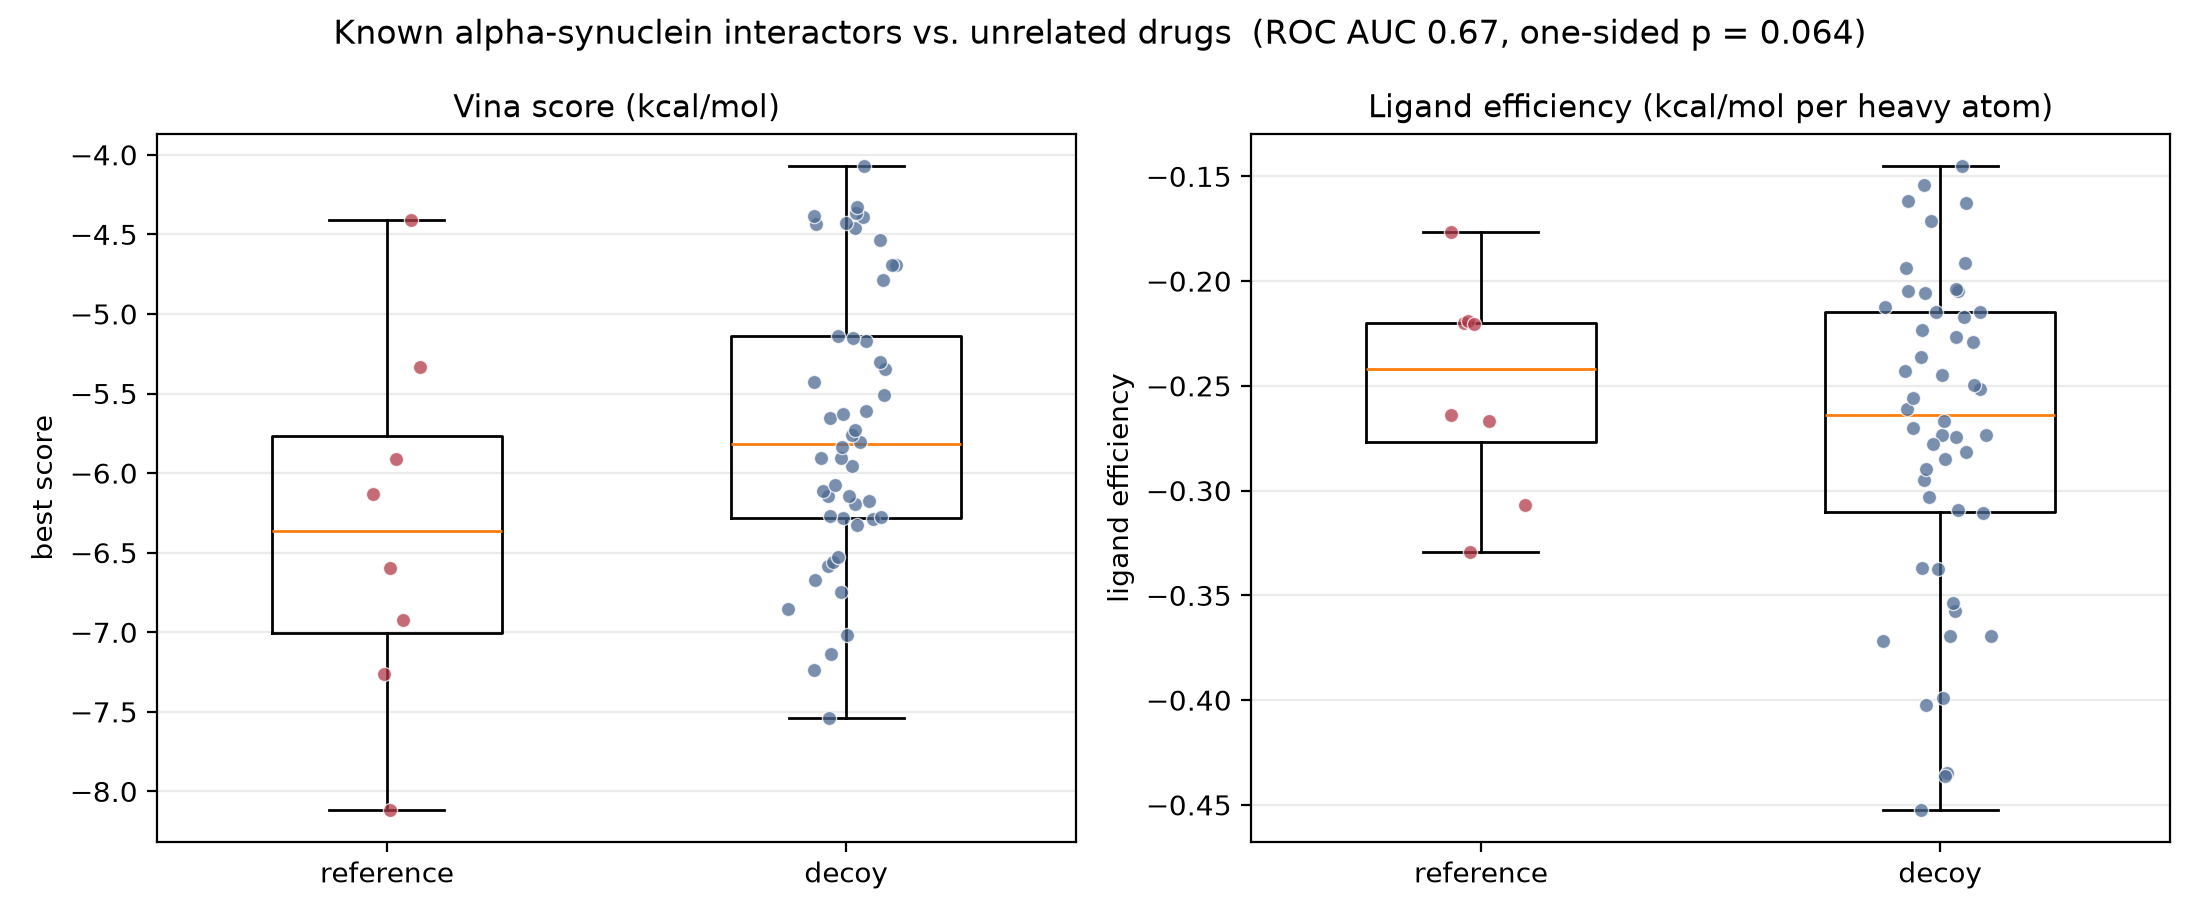

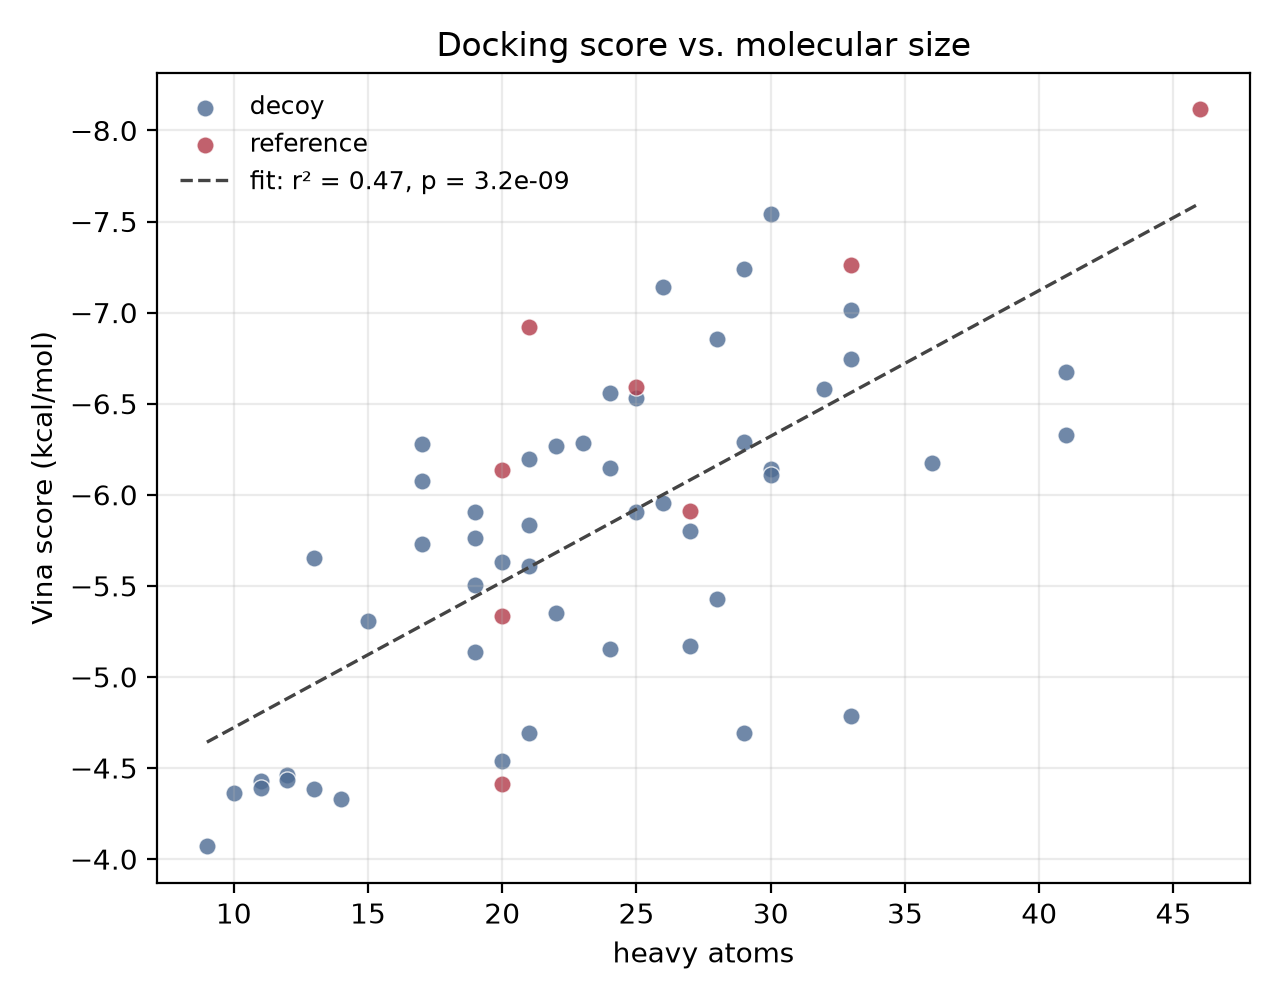

In [7]:
display(Image(filename=str(RESULTS / "figures" / "reference_vs_decoy.png")))
display(Image(filename=str(RESULTS / "figures" / "size_confound.png")))

## 5. Side analysis: ESM-2 contact maps for the familial mutants

Separate from the docking. Does a protein language model predict different
residue-residue contacts for A30P, E46K and A53T, the three point mutations
that cause familial Parkinson's disease?

The question only means something against a baseline, because any single
substitution perturbs the map a little. Three **control substitutions** with no
reported Parkinson's link are run alongside to supply one.

Run with ESM-2 150M in its own environment (`environment-esm.yml`).

,group,map_correlation,embedding_cosine_to_wt,max_abs_change,frobenius_norm
A30P,familial,0.996885,0.999726,0.18090,0.7663
E46K,familial,0.994888,0.999391,0.29924,0.9862
A53T,familial,0.998275,0.999879,0.16588,0.5712
A19G,control,0.997570,0.999869,0.21238,0.6867
V40A,control,0.996121,0.999912,0.36464,0.8544
T75S,control,0.998722,0.999936,0.26020,0.4951


median change, familial: 0.7663
median change, control:  0.6867


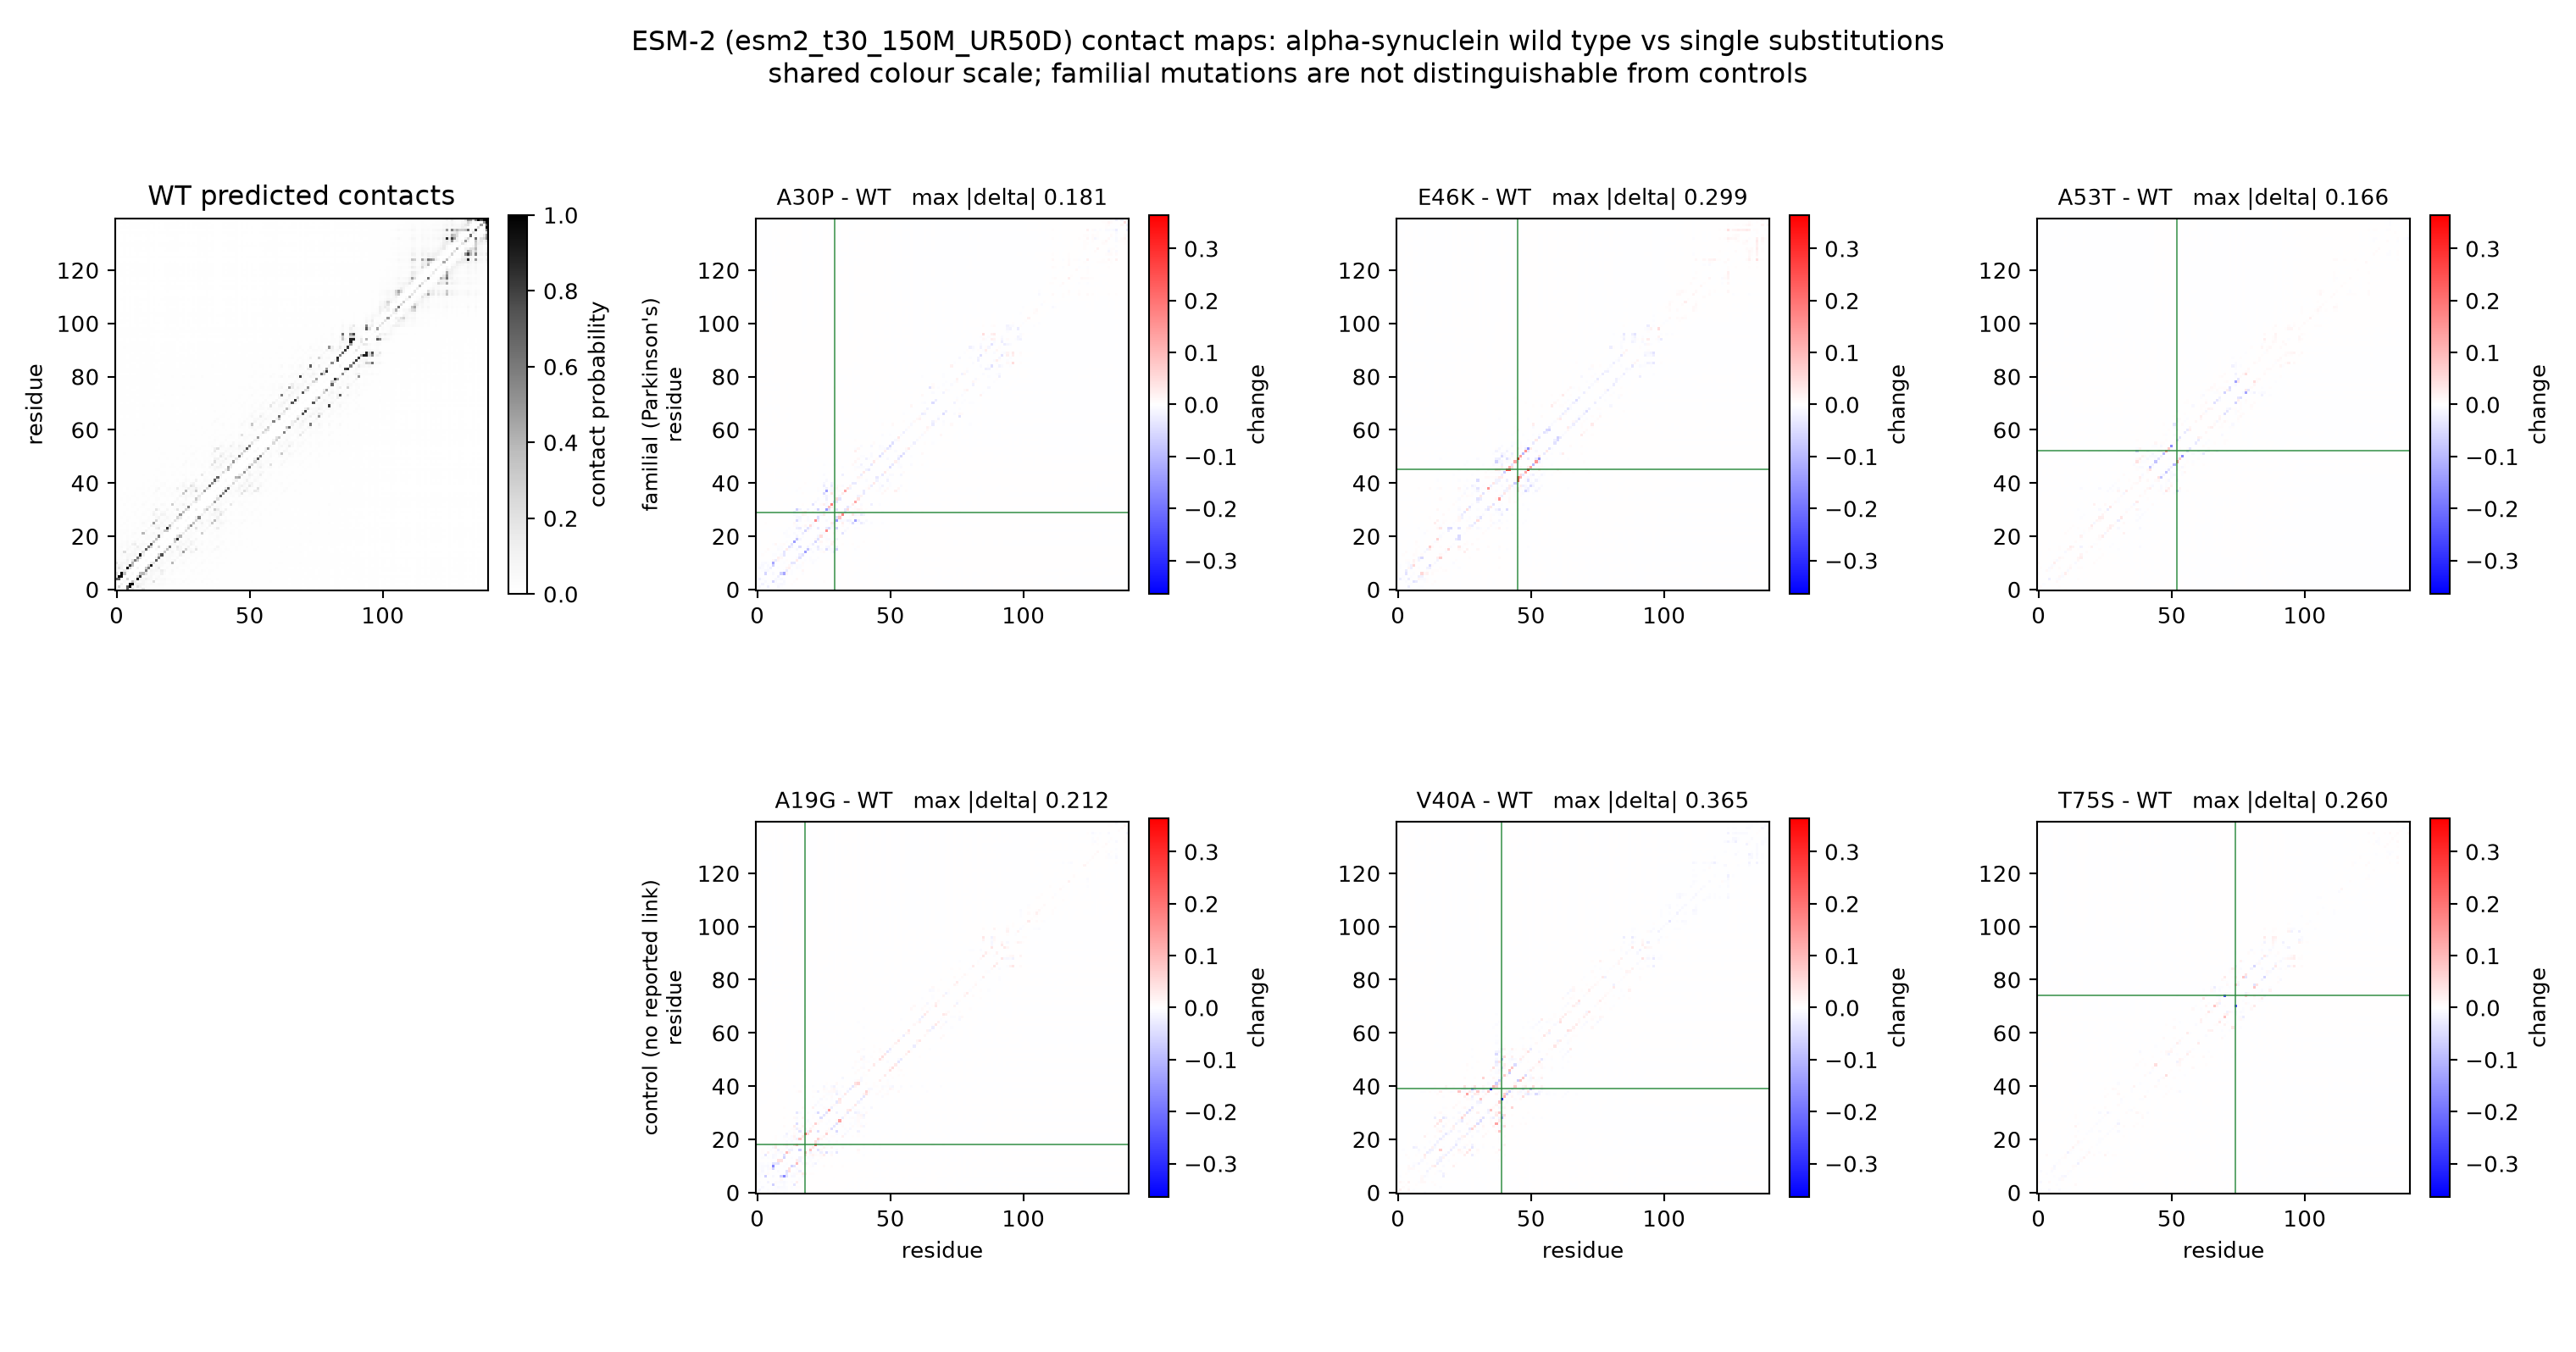

In [8]:
esm = json.loads((RESULTS / "esm_mutant_summary.json").read_text())

familial = pd.DataFrame(esm["mutants"]).T.assign(group="familial")
controls = pd.DataFrame(esm["controls"]).T.assign(group="control")
display(pd.concat([familial, controls])[[
    "group", "map_correlation", "embedding_cosine_to_wt",
    "max_abs_change", "frobenius_norm",
]])

print("median change, familial:", esm["comparison"]["familial_median_frobenius"])
print("median change, control: ", esm["comparison"]["control_median_frobenius"])

display(Image(filename=str(RESULTS / "figures" / "esm_contact_maps.png")))

## 6. What this does and does not show

**Does not show, and cannot:**

- *Binding affinities.* A Vina score is a scoring-function output in kcal/mol.
  It is not a measured free energy and does not convert to one.
- *Hits.* Nothing here was tested against protein. No compound in this
  repository has been shown to do anything to alpha-synuclein by this work.
- *Clean negatives.* The decoys are drugs with no published alpha-synuclein
  interaction, which is not the same as a measured non-interaction. Some may
  bind.

**Other limits worth stating:**

- The receptor is rigid; a fibril surface in water is not.
- No solvent, no ions, no entropy beyond what the scoring function approximates.
- One cryo-EM polymorph. Alpha-synuclein fibrils are polymorphic, and a
  different polymorph would give a different site and different numbers.
- The reference set is eight compounds, which is small for a ranking statistic.
  The confidence interval on the AUC is wide.